# Landsat 8 band ratios over the Pilbara, Australia

This notebook finds a clear Landsat 8 scene over the Hamersley iron-ore province near Newman, Western Australia, and runs **every ratio and RGB composite Landsat 8 supports** with `rockbands`. It uses the same steps as the Sentinel-2 notebook, so the differences between the two sensors stand out.

1. Search the catalogue
2. Identify the sensor and its bands
3. Load the bands
4. Convert to reflectance and mask clouds
5. Run one ratio
6. See what Landsat 8 can and cannot run
7. Run every ratio and composite
8. One ratio, every sensor

> **Where the data comes from.** The scenes are read from the [Microsoft Planetary Computer](https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2), which serves USGS Landsat Collection 2 Level-2 with no account or credentials. The AWS copy (Earth Search) is in a *requester-pays* bucket: reading it needs AWS credentials and bills the transfer to your account. To use it instead, install `boto3`, restart the kernel, and replace the catalogue lines as shown in the last cell of this notebook.

In [ ]:
%pip install -q -e .. pystac-client planetary-computer odc-stac rioxarray matplotlib pandas

In [1]:
import rockbands as rb
import odc.stac
import pandas as pd
import planetary_computer
import rioxarray
from pystac_client import Client

## 1. Search the catalogue

The `landsat-c2-l2` collection mixes Landsat 4 to 9. Each item states its platform, and `get_sensor` turns that into a sensor key, so we can keep only Landsat 8 scenes without caring how the catalogue spells the name.

In [2]:
bbox = [119.55, -23.45, 119.85, -23.20]

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)
search = catalog.search(
    collections=["landsat-c2-l2"],
    bbox=bbox,
    datetime="2025-05-01/2025-09-30",
    query={"eo:cloud_cover": {"lt": 10}},
)
scenes = [i for i in search.items() if rb.get_sensor(i.properties["platform"]).key == "l8"]
item = min(scenes, key=lambda i: i.properties["eo:cloud_cover"])

item.id, item.properties["datetime"], item.properties["eo:cloud_cover"]

('LC08_L2SP_111076_20250930_02_T1', '2025-09-30T01:57:06.366847Z', 0.0)

## 2. Identify the sensor and its bands

Landsat 8 puts NIR in band 5 where Sentinel-2 uses band 8, and its SWIR bands are 6 and 7 where Sentinel-2 uses 11 and 12. `compare_bands` makes these differences visible, and it is what the ratio functions use to pick the right band for each role. Landsat 9 is listed too: it has the same layout as Landsat 8.

In [3]:
sensor = rb.get_sensor(item.properties["platform"])
rb.compare_bands(["s2", sensor, "l9"], standards=["B", "G", "R", "N", "S1", "S2"])

**Band comparison (nm). '-' means the sensor has no band for that role.**

| Role | Description | Nominal (nm) | s2 | l8 | l9 |
| --- | --- | --- | --- | --- | --- |
| B | Blue | 450-530 | B2 (460-525) | B2 (450-510) | B2 (450-510) |
| G | Green | 510-600 | B3 (542-577) | B3 (530-590) | B3 (530-590) |
| R | Red | 620-690 | B4 (650-680) | B4 (640-670) | B4 (640-670) |
| N | NIR | 760-900 | B8 (780-885) | B5 (850-880) | B5 (850-880) |
| S1 | SWIR 1 | 1550-1750 | B11 (1569-1659) | B6 (1570-1650) | B6 (1570-1650) |
| S2 | SWIR 2 | 2080-2350 | B12 (2115-2289) | B7 (2110-2290) | B7 (2110-2290) |

STAC calls the band files `red`, `nir08`, `swir16`. This mapping connects them to Landsat band ids, and the table checks it against the wavelengths the library holds.

In [4]:
assets = {
    "coastal": "B1", "blue": "B2", "green": "B3", "red": "B4",
    "nir08": "B5", "swir16": "B6", "swir22": "B7",
}

pd.DataFrame(
    [(asset, band, sensor.band(band).standard, sensor.band(band).wavelength_nm) for asset, band in assets.items()],
    columns=["stac_asset", "band", "role", "wavelength_nm"],
)

,stac_asset,band,role,wavelength_nm
0,coastal,B1,A,"(430, 450)"
1,blue,B2,B,"(450, 510)"
2,green,B3,G,"(530, 590)"
3,red,B4,R,"(640, 670)"
4,nir08,B5,N,"(850, 880)"
5,swir16,B6,S1,"(1570, 1650)"
6,swir22,B7,S2,"(2110, 2290)"


## 3. Load the bands

`qa_pixel` is the Landsat quality band, used next for the cloud mask. Landsat bands are all 30 m, so no resampling is needed.

In [5]:
ds = odc.stac.load([item], bands=[*assets, "qa_pixel"], bbox=bbox, resolution=30, chunks={})
ds = ds.isel(time=0).compute().rename(assets)
ds

<xarray.Dataset> Size: 16MB
Dimensions:      (y: 948, x: 1045)
Coordinates:
  * y            (y) float64 8kB -2.569e+06 -2.569e+06 ... -2.598e+06 -2.598e+06
  * x            (x) float64 8kB 1.468e+05 1.468e+05 ... 1.781e+05 1.781e+05
    spatial_ref  int32 4B 32651
    time         datetime64[us] 8B 2025-09-30T01:57:06.366847
Data variables:
    B1           (y, x) uint16 2MB 8566 8656 8881 8887 ... 8743 8764 8727 8733
    B2           (y, x) uint16 2MB 8923 8925 9167 9190 ... 9092 9116 9077 9041
    B3           (y, x) uint16 2MB 10363 10335 10525 10559 ... 10411 10364 10306
    B4           (y, x) uint16 2MB 12381 12243 12583 12874 ... 13606 13708 13539
    B5           (y, x) uint16 2MB 13269 13154 14059 14747 ... 16198 16387 16312
    B6           (y, x) uint16 2MB 17914 17436 18042 18993 ... 20603 20749 20622
    B7           (y, x) uint16 2MB 14107 13402 14265 15197 ... 18775 18927 18771
    qa_pixel     (y, x) uint16 2MB 21824 21824 21824 21824 ... 21824 21824 21824

## 4. Convert to reflectance and mask clouds

`dn_to_reflectance` applies the Collection 2 Level-2 scaling (`DN × 0.0000275 − 0.2`) and turns no-data into NaN. Level-2 reflectance can fall slightly outside 0 to 1 over very dark or very bright pixels, so it is clipped. In `qa_pixel`, bits 0 to 5 flag fill, dilated cloud, cirrus, cloud, cloud shadow and snow, so any pixel with one of them set is masked.

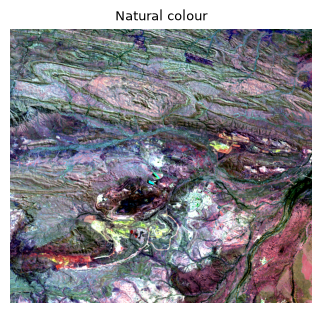

In [ ]:
clear = (ds["qa_pixel"] & 0b111111) == 0
bands = ds.drop_vars("qa_pixel").map(lambda band: rb.dn_to_reflectance(band, sensor, clip=(0, 1))).where(clear)

rb.plot_composites({"natural_colour": rb.natural_colour(bands, sensor=sensor)}, ncols=1);



To export the RGB to a Geotiff, just follow these steps:

In [8]:
rgb = rb.natural_colour(bands, sensor=sensor)
image = (rgb.clip(0, 0.3) / 0.3 * 255).fillna(0).astype("uint8")
image.rio.to_raster("natural_colour.png", dtype="uint8")

## 5. Run one ratio

`clay_sulphate_mica_marble` is `(S1/S2)/(N/R)`: the SWIR ratio that responds to clay, sulphate and mica absorption, divided by NIR over red. On Landsat 8 it is evaluated as `(B6/B7)/(B5/B4)`.

(B6/B7)/(B5/B4)


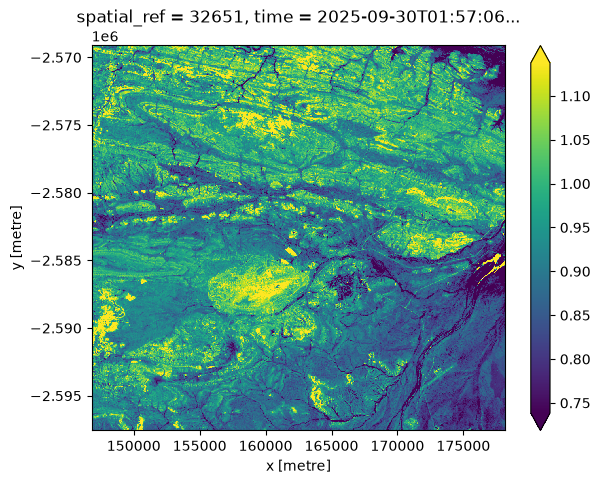

In [9]:
clay = rb.clay_sulphate_mica_marble(bands, sensor=sensor)
print(rb.translate("clay_sulphate_mica_marble", sensor))
clay.plot.imshow(robust=True, cmap="viridis", size=5);

## 6. See what Landsat 8 can and cannot run

Landsat 8 has no red-edge bands and no narrow NIR band, so ratios that need them are refused with a message that names the missing band and the sensors that do have it.

In [10]:
try:
    rb.moisture_index(bands, sensor=sensor)
except rb.BandNotAvailableError as error:
    print(error)

rb.ratio_support(["s2", "l8"], kind="composite")

'moisture_index' needs N2 (NIR 2 (narrow), 850-880 nm), which Landsat 8 OLI/TIRS does not have. Sensors that can run it: s2.


**Ratio support by sensor**

| Ratio | Kind | Formula | s2 | l8 |
| --- | --- | --- | --- | --- |
| natural_colour | composite | R, G, B | ok | ok |
| colour_infrared | composite | N, R, G | ok | ok |
| false_colour_urban | composite | S2, S1, R | ok | ok |
| agriculture | composite | S1, N, B | ok | ok |
| geology | composite | S2, R, B | ok | ok |
| bathymetric | composite | R, G, A | ok | ok |
| atmospheric_penetration | composite | S2, S1, N2 | ok | needs N2 |
| swir_composite | composite | S2, N2, R | ok | needs N2 |
| swir_2_composite | composite | B, S1, S2 | ok | ok |
| ross_smail_getech | composite | S1/R, R/B, S2/S1 | ok | ok |
| gad_kusky_1 | composite | S1/R, S2/S1, S1/B | ok | ok |
| gad_kusky_2 | composite | S2/S1, S1/N, R/B | ok | ok |
| zohair_2019 | composite | S1/S2, S1/N, R/B | ok | ok |
| pour | composite | R/B, R/S1, S1/S2 | ok | ok |
| sultan_gomez | composite | S1/S2, S1/B, (S1/N)*(R/N) | ok | ok |
| abrams_1983 | composite | S1/S2, N/S1, R/B | ok | ok |
| mineral_map | composite | S2/N, N/S2, S1/R | ok | ok |

## 7. Run every ratio and composite

`compute_all` evaluates everything the sensor supports. Compared with Sentinel-2 there are fewer entries, because the ones that need the narrow NIR band (`N2`) are left out.

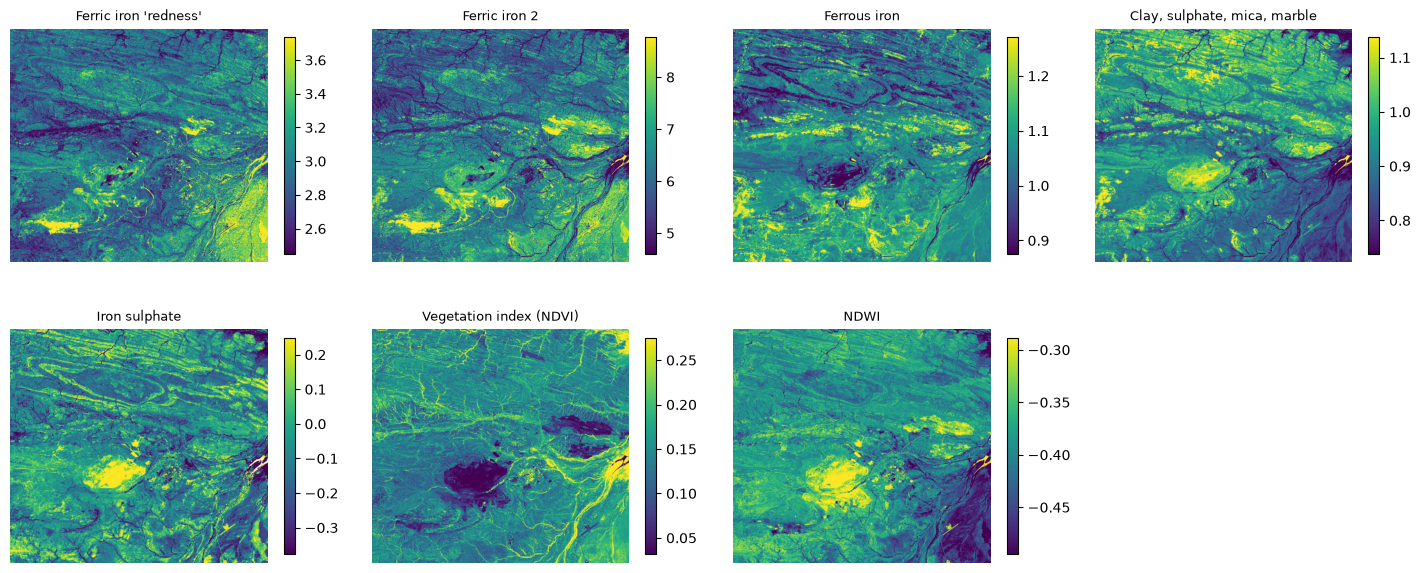

In [11]:
ratios = rb.compute_all(bands, sensor, kind="ratio")
rb.plot_ratios(ratios, ncols=4);

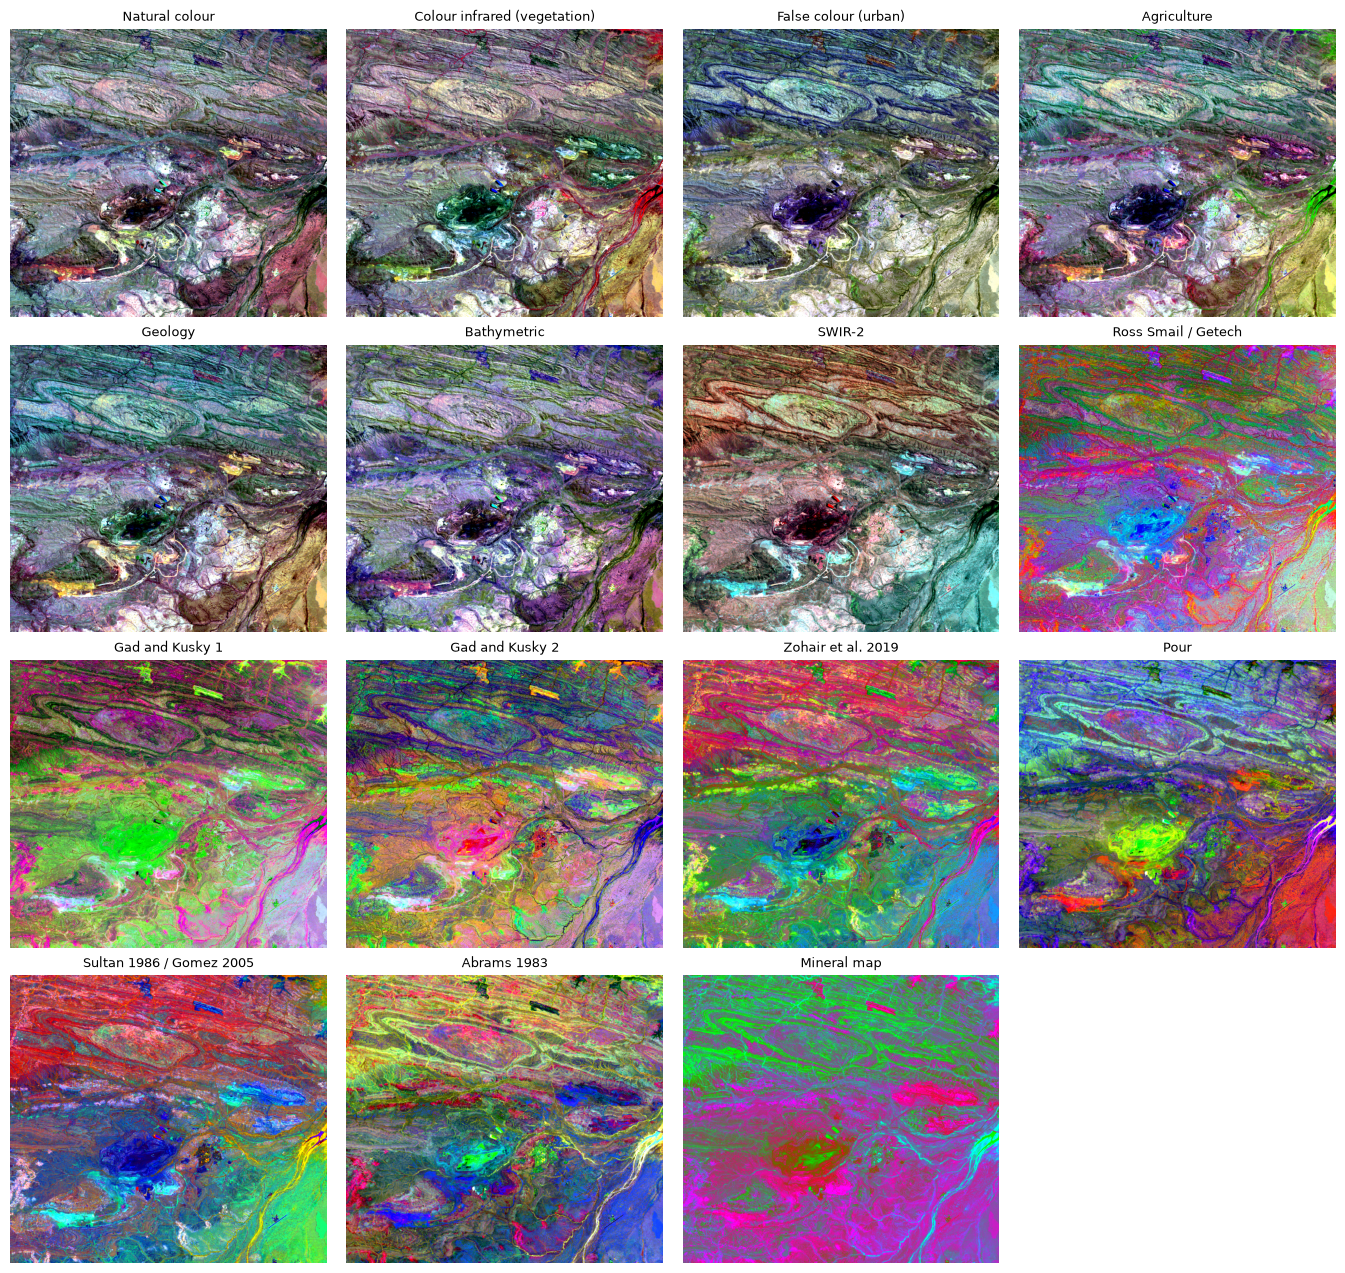

In [12]:
composites = rb.compute_all(bands, sensor, kind="composite")
rb.plot_composites(composites, ncols=4);

## 8. One ratio, every sensor

The same ratio is a different set of bands on each satellite. `translate` shows it for every sensor that can run `clay_sulphate_mica_marble`, and `ferric_iron_redness` can be saved like any xarray result.

In [13]:
clay_by_sensor = pd.Series(
    {key: rb.translate("clay_sulphate_mica_marble", key) for key in ["s2", "l5", "l7", "l8", "l9"]},
    name="formula",
)

rb.ferric_iron_redness(bands, sensor=sensor).rio.write_nodata(float("nan")).rio.to_raster("ferric_iron_redness_l8.tif")
clay_by_sensor

s2    (B11/B12)/(B8/B4)
l5      (B5/B7)/(B4/B3)
l7      (B5/B7)/(B4/B3)
l8      (B6/B7)/(B5/B4)
l9      (B6/B7)/(B5/B4)
Name: formula, dtype: str